# 03 · Conversion-Funnel Analysis

> **Synthetic data disclosure.** All data in this project is generated by `python/generate_sample_data.py` (seed 42). It is realistic in structure but does **not** describe any real company. Findings demonstrate the analytical method, not real performance.

## Funnel definition (session-based, ordered)

| Stage | A session reaches the stage when… |
|---|---|
| 1 · Session | it is a valid session |
| 2 · Product view | it has ≥ 1 `product_view` |
| 3 · Add to cart | it has an `add_to_cart` **at or after** its first product view |
| 4 · Checkout started | it has a `begin_checkout` at or after the first qualifying add-to-cart |
| 5 · Purchase | it has a `purchase` at or after the first qualifying checkout |

Each session counts **once** per stage, and only if it reached the previous stage, so counts can never increase down the funnel. The same logic is implemented in `python/metrics.py`, `sql/05_conversion_funnel.sql`, and as pre-computed flags (`reached_*`) used by the DAX measures.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "python"))
import pandas as pd, numpy as np
from IPython.display import Image, Markdown, display
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
FIG = ROOT / "reports" / "figures"; MET = ROOT / "reports" / "metrics"
def show(name, width=900): display(Image(filename=str(FIG / name), width=width))
def pct(df, cols): return df.style.format({c: "{:.2%}" for c in cols})
import analysis as an, metrics as m
fs, ft, fe = an.load_model()
kpis, recon, T = an.run_all()

## 1. Overall funnel

In [2]:
f = m.funnel_summary(fs)
f.style.format({'pct_of_sessions':'{:.1%}','conversion_to_next':'{:.1%}','drop_off_rate':'{:.1%}','sessions_lost':'{:,.0f}'})

,stage_order,stage,sessions,pct_of_sessions,conversion_to_next,drop_off_rate,sessions_lost
0,1,Session,35822,100.0%,54.1%,45.9%,"16,445"
1,2,Product view,19377,54.1%,19.9%,80.1%,"15,516"
2,3,Add to cart,3861,10.8%,47.9%,52.1%,"2,010"
3,4,Checkout started,1851,5.2%,48.0%,52.0%,963
4,5,Purchase,888,2.5%,nan%,nan%,nan


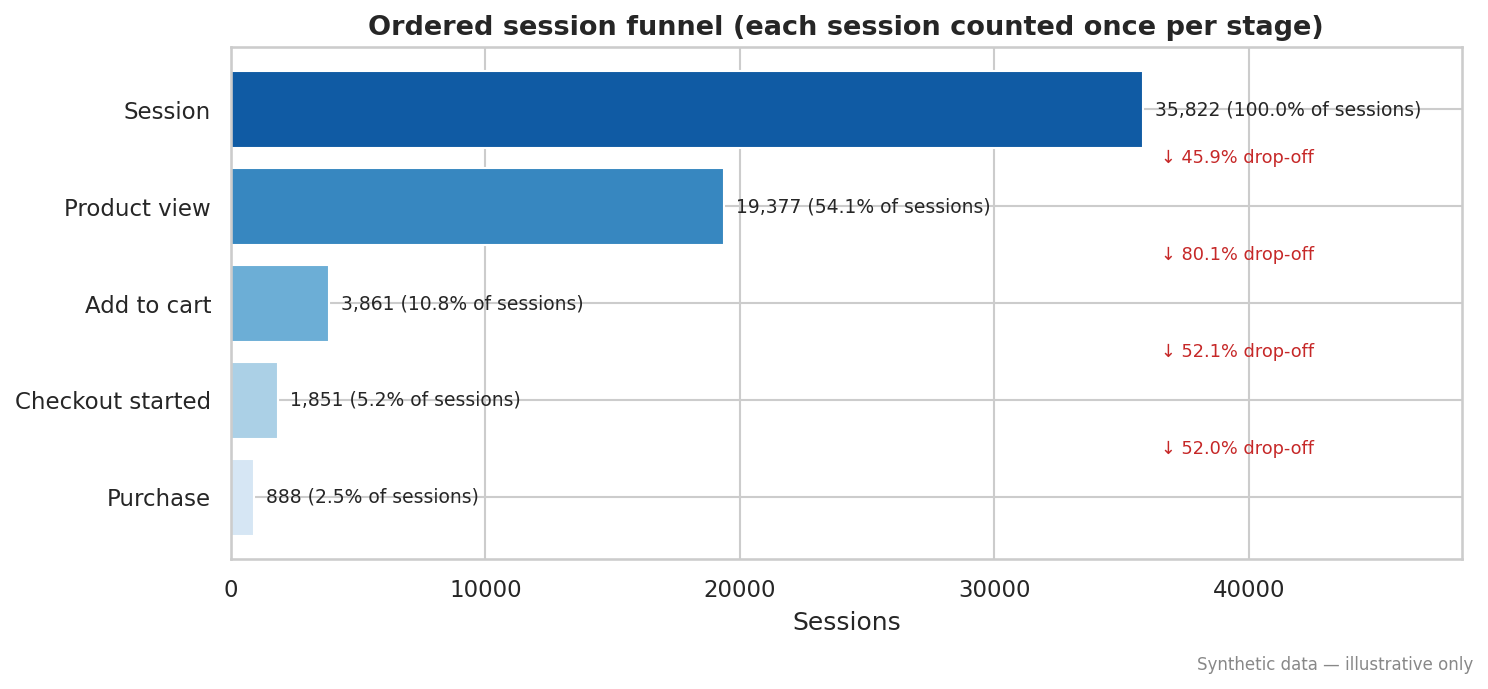

In [3]:
show('10_conversion_funnel.png', 850)

In [4]:
x = f.dropna(subset=['drop_off_rate'])
print('Largest % drop-off :', x.loc[x.drop_off_rate.idxmax(), 'stage'], '→ next', f"{x.drop_off_rate.max():.1%}")
print('Largest absolute loss:', x.loc[x.sessions_lost.idxmax(), 'stage'], '→ next', f"{x.sessions_lost.max():,.0f} sessions")

Largest % drop-off : Product view → next 80.1%
Largest absolute loss: Session → next 16,445 sessions


**Where the funnel leaks.**
* The largest **percentage** drop is *Product view → Add to cart*: 80% of product-viewing sessions do not add anything to the cart.
* The largest **absolute** loss is *Session → Product view* (16.4k sessions never view a product), closely followed by product view → cart (15.5k). Much of the first loss is expected: blog readers and bounce traffic.
* Once a cart exists, about half of sessions start checkout, and about half of checkouts complete. That second-half leakage is where the device split matters most (below).

## 2. Why the ordered definition matters

In [5]:
unordered = {s: int(fs[c].sum()) for s, c in [('Product view','has_product_view_event'),('Add to cart','has_add_to_cart_event'),('Checkout started','has_begin_checkout_event'),('Purchase','has_purchase_event')]}
cmp = f.set_index('stage')[['sessions']].rename(columns={'sessions':'ordered'})
cmp['event_present_unordered'] = pd.Series(unordered)
cmp

,ordered,event_present_unordered
stage,,
Session,35822,NaN
Product view,19377,19377.0
Add to cart,3861,3861.0
Checkout started,1851,1851.0
Purchase,888,913.0


Only the purchase stage differs: 25 sessions logged `purchase` **before** `begin_checkout`. Counting the mere presence of the event would include them; the ordered definition does not.

## 3. Reconciling the funnel with the Purchasing Sessions KPI

In [6]:
pd.Series(recon)

purchasing_sessions_transaction_based         913
funnel_purchase_stage_event_based             888
purchase_event_before_checkout_sessions        25
transaction_without_purchase_event             13
ordered_purchase_without_valid_transaction     13
dtype: int64

`Purchasing Sessions` (913) comes from **valid transactions**; the funnel's *Purchase* stage (888) comes from **ordered events**:

913 transaction-based − 25 sequence violations − 13 transactions with no purchase event (tracking loss) + 13 ordered purchases whose transaction was quarantined = **888**.

Both numbers are correct for their purpose. Executive KPIs and revenue use transactions. Funnel diagnostics use ordered events. The dashboard labels them distinctly so they are never compared as if they were the same metric.

## 4. Funnel by device

In [7]:
fd = T['funnel_by_device']
fd.pivot(index=['stage_order','stage'], columns='device_label', values='sessions')

,device_label,Desktop,Mobile,Tablet
stage_order,stage,,,
1,Session,13733,19832,2150
2,Product view,7597,10568,1158
3,Add to cart,1651,1960,239
4,Checkout started,873,866,104
5,Purchase,502,320,61


In [8]:
fd.pivot(index=['stage_order','stage'], columns='device_label', values='conversion_to_next').dropna().style.format('{:.1%}')

,device_label,Desktop,Mobile,Tablet
stage_order,stage,,,
1,Session,55.3%,53.3%,53.9%
2,Product view,21.7%,18.5%,20.6%
3,Add to cart,52.9%,44.2%,43.5%
4,Checkout started,57.5%,37.0%,58.7%


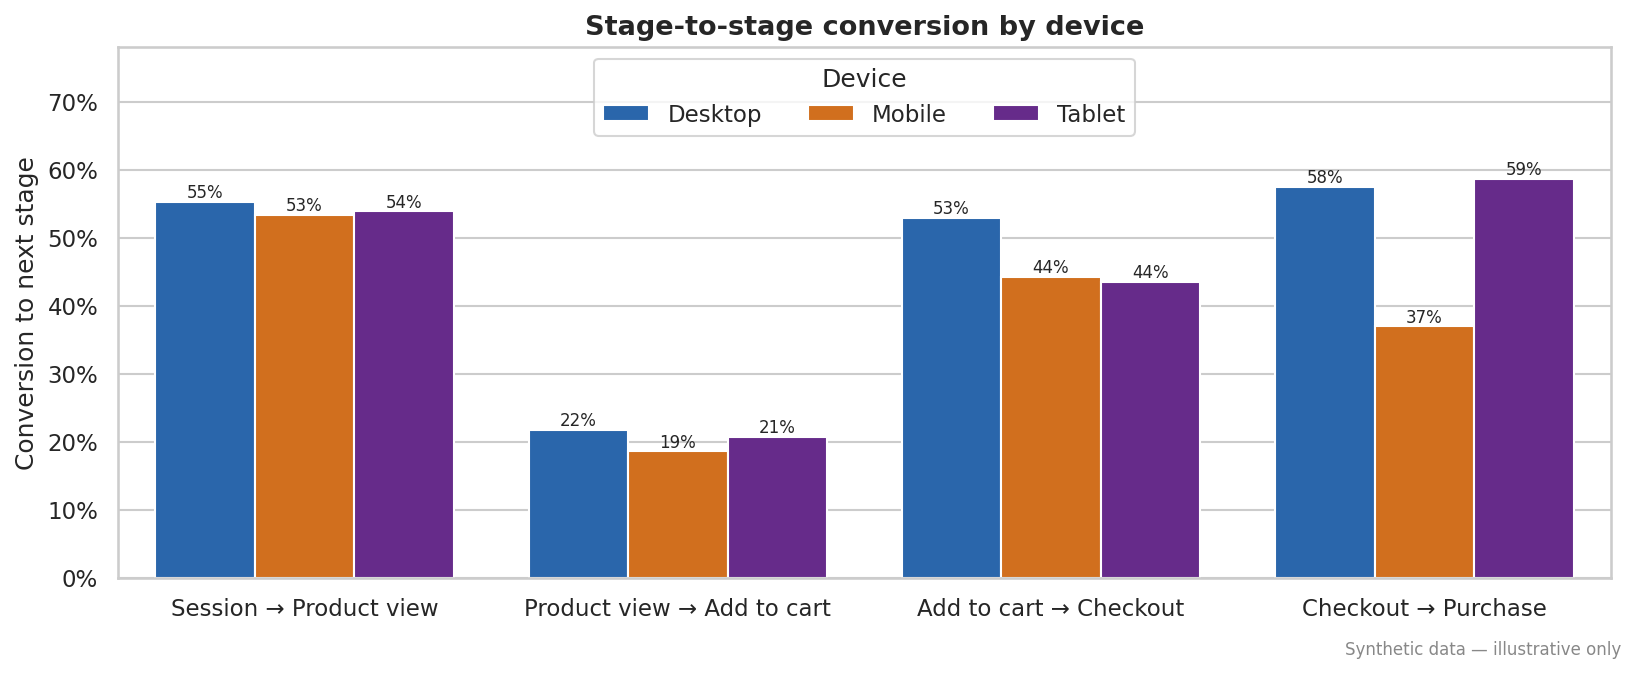

In [9]:
show('11_funnel_by_device.png', 950)

**Mobile's gap is concentrated late in the funnel.**
* Top of funnel is similar: 53–55% of sessions view a product on every device.
* Product view → cart: mobile 18.5% vs desktop 21.7% (modest gap).
* Cart → checkout: mobile 44.2% vs desktop 52.9%.
* **Checkout → purchase: mobile 37.0% vs desktop 57.5%.** Mobile starts almost as many checkouts as desktop (866 vs 873) but completes far fewer (320 vs 502).

A 20-point gap at the final step, after the user has already shown purchase intent, points at checkout UX on small screens (form length, payment options, errors, page speed). Those are **hypotheses**: the data shows *where* users leave, not *why*. Session recordings, form analytics, and an A/B test of a simplified mobile checkout are needed to confirm the cause.

## 5. Funnel by channel

In [10]:
T['funnel_by_channel'].pivot(index=['stage_order','stage'], columns='channel_group', values='conversion_to_next').dropna().style.format('{:.1%}')

,channel_group,Direct,Email,Organic Search,Organic Social,Paid Search,Paid Social,Referral
stage_order,stage,,,,,,,
1,Session,52.8%,61.2%,45.3%,57.0%,65.8%,57.1%,54.3%
2,Product view,25.3%,36.5%,18.2%,9.0%,25.1%,11.1%,14.9%
3,Add to cart,45.7%,48.7%,48.8%,50.0%,47.1%,48.0%,55.5%
4,Checkout started,47.6%,54.0%,48.2%,29.5%,50.8%,37.7%,51.3%


Paid Social and Organic Social lose most users at product view → add to cart (11% and 9% vs 25–37% for Email, Direct and Paid Search) and again at checkout. Social visitors browse but rarely show purchase intent, consistent with a targeting/offer mismatch rather than a site defect that would affect all channels.

## 6. Upper-bound opportunity sizing (illustrative, not a forecast)

In [11]:
T_opp = pd.read_csv(MET/'opportunity_sizing.csv')
T_opp.style.format({'additional_purchases':'{:,.0f}','aov_used':'${:.2f}','additional_revenue':'${:,.0f}'})

,scenario,basis,additional_purchases,aov_used,additional_revenue,period
0,Mobile checkout→purchase rate matches desktop,866 mobile checkouts × (57.5% − 37.0%),178,$68.39,"$12,172","Jan–Jun 2025 (observed, synthetic)"
1,Mobile cart→checkout rate matches desktop (at current mobile checkout completion),"1,960 mobile carts × (52.9% − 44.2%) × 37.0%",63,$68.39,"$4,306","Jan–Jun 2025 (observed, synthetic)"
2,Paid Social CVR closes half the gap to site average,"7,071 sessions × (1.87% − 1.19%)",48,$75.57,"$3,636","Jan–Jun 2025 (observed, synthetic)"


These scenarios ask what the **observed** six months would have looked like if a gap were fully closed, holding everything else constant. They rank where to test first; they are not a promise of uplift. Real improvements should be measured with controlled experiments.